# STATS 425 · Week 6 lab
**Rewarding calibrated confidence**  
**TA:** Ali Kaazempur-Mofrad

In Week 4, we trained a policy with a verifier's reward: sample an answer, check it, update. In Week 5, we subtracted a baseline from each reward and compared responses sampled for the same prompt (group-relative advantages). Both weeks asked only one thing of the model: be correct. Today, the model must also **report how likely it is to be correct**, and we reward that report with the calibration reward previewed at the end of Week 5.

We use a noisy version of Week 4's "Which number is largest?" task. The model sees each number with random noise added, so even the best possible policy is sometimes wrong, and the right confidence depends on how close the observed numbers are. Each response has two parts: an answer (`A`, `B`, or `C`) and a confidence level.

| Section | Question we answer |
|---|---|
| 1. Correct versus confident | What does it mean for reported confidence to be calibrated? |
| 2. Proper scoring rules | Which rewards make an honest confidence report the best report? |
| 3. Rewarding an answer and a confidence | How does one sampled response earn a calibration reward and an advantage? |
| 4. Training with and without the calibration reward | Does the calibration reward improve calibration without hurting accuracy? |
| 5. Try it | How do the noise level and the allowed confidence levels change what is learned? |

**Set up the notebook:** The cell below imports the libraries and sets a random seed so the results are repeatable; exact numbers may differ slightly across PyTorch versions.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("torch") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch>=2.8,<3"])

import itertools
import random

import matplotlib.pyplot as plt
import torch
from torch import nn  # PyTorch's neural-network module
from torch.distributions import Categorical

SEED = 425
torch.manual_seed(SEED)
torch.set_num_threads(1)

COLORS = ("#2874A6", "#C0392B", "#7F8C8D")

print(f"Setup complete. PyTorch {torch.__version__}")

Setup complete. PyTorch 2.8.0+cu128


## 1 · Correct versus confident

**A noisy version of Week 4's task:** The true prompt still contains three different integers from 1 through 9, $x=(x_A,x_B,x_C)$. The model, however, sees each number with independent Gaussian noise added:

$$
\tilde x_j = x_j+\sigma\varepsilon_j,
\qquad \varepsilon_j\sim\mathcal N(0,1)\ \text{independently},
\qquad j\in\{A,B,C\}
$$

We use $\sigma=1.5$. The verifier knows the true numbers and judges the answer on them: correctness is

$$
c=\mathbf{1}\{\text{the chosen answer holds the largest true number}\}
$$

Since the model sees only $\tilde x$, it can be wrong even when it picks the largest number it sees. A prompt now looks like this:

```text
Which number is largest?
A: 2.4    B: 7.9    C: 6.6
Respond with A, B, or C, then your confidence that the answer is correct.
```

A response is an answer and a confidence, for example `B 0.7`. The confidence $q$ is the model's **reported probability that its answer is correct**. We allow five levels, $q\in\{0.1,0.3,0.5,0.7,0.9\}$.

**Generate noisy prompts:** We keep Week 4's split: 64 groups of three numbers for training and 20 groups for testing, each in all six orders. During training, every time a prompt is used it receives fresh noise. For testing, each of the 120 test prompts receives 10 fixed noise draws, giving 1,200 observed test prompts; every method in Sections 1–4 is scored on these same observations. The code prints one observed prompt and a few test examples.

In [2]:
LETTERS = ("A", "B", "C")
SIGMA = 1.5        # standard deviation of the observation noise
TEST_DRAWS = 10    # fixed noise draws per test prompt

groups = list(itertools.combinations(range(1, 10), 3))
random.Random(SEED).shuffle(groups)
train_groups, test_groups = groups[:64], groups[64:]


def expand_orders(groups):
    return torch.tensor([
        ordering
        for group in groups
        for ordering in itertools.permutations(group)
    ], dtype=torch.float32)


def observe(true_numbers, sigma, generator=None):
    # Add independent Gaussian noise to every number the model sees.
    noise = torch.randn(true_numbers.shape, generator=generator)
    return true_numbers + sigma * noise


def format_prompt(observed):
    options = "    ".join(f"{letter}: {value:.1f}" for letter, value in zip(LETTERS, observed))
    return (f"Which number is largest?\n{options}\n"
            "Respond with A, B, or C, then your confidence that the answer is correct.")


def correctness(true_numbers, answers):
    # c = 1 if the chosen answer holds the largest TRUE number, otherwise 0.
    chosen = true_numbers.gather(-1, answers.unsqueeze(-1)).squeeze(-1)
    return (chosen == true_numbers.max(dim=-1).values).float()


train_numbers = expand_orders(train_groups)
test_numbers = expand_orders(test_groups)
test_true = test_numbers.repeat(TEST_DRAWS, 1)
test_observed = observe(test_true, SIGMA, torch.Generator().manual_seed(SEED))

print(f"Training set: {len(train_groups)} groups x 6 orders = {len(train_numbers)} prompts (fresh noise at each use)")
print(f"Test set: {len(test_numbers)} prompts x {TEST_DRAWS} noise draws = {len(test_observed)} observed prompts")
print("-" * 72)
print("EXAMPLE TEST PROMPT (the model sees only the observed numbers)")
print(format_prompt(test_observed[0].tolist()))
print("-" * 72)
print(f"{'True numbers':<16}{'Observed numbers':<22}{'Largest observed':>18}{'Correct (c)':>14}")
for i in range(0, 8 * 151, 151):
    answer = test_observed[i].argmax()
    true_text = ", ".join(f"{int(value)}" for value in test_true[i])
    observed_text = ", ".join(f"{value:.1f}" for value in test_observed[i])
    print(f"{true_text:<16}{observed_text:<22}{LETTERS[answer]:>18}"
          f"{int(correctness(test_true[i], answer)):>14}")

Training set: 64 groups x 6 orders = 384 prompts (fresh noise at each use)
Test set: 120 prompts x 10 noise draws = 1200 observed prompts
------------------------------------------------------------------------
EXAMPLE TEST PROMPT (the model sees only the observed numbers)
Which number is largest?
A: 4.8    B: 5.4    C: 10.0
Respond with A, B, or C, then your confidence that the answer is correct.
------------------------------------------------------------------------
True numbers    Observed numbers        Largest observed   Correct (c)
5, 6, 9         4.8, 5.4, 10.0                         C             1
1, 9, 6         1.2, 8.4, 10.6                         C             0
6, 5, 8         6.3, 4.8, 9.7                          C             1
3, 4, 1         0.9, 3.5, 2.3                          B             1
9, 5, 6         7.6, 3.6, 6.8                          A             1
9, 6, 1         10.7, 8.5, -0.5                        A             1
2, 3, 4         4.1, 3.2, 5.6

Each row is one observed test prompt. Noise can move an observed value outside 1–9 (for example, 10.6 or −0.5). In the second row, noise made `C` (true value 6) look larger than `B` (true value 9), so the largest-observed answer is wrong, and the verifier, which uses the true numbers, gives $c=0$. In the other rows, noise did not change which number looks largest.

**Measure how hard each prompt is:** A natural answer rule is to choose the largest **observed** number. Because each group appears in all six orders and the noise is Gaussian with the same $\sigma$ for every position, the letter with the largest observed value is also the letter most likely to hold the largest true value, so no rule is correct more often on average. Even so, it fails when noise reverses the order of the two largest numbers, which is more likely when they look close.

We summarize difficulty by the **observed gap**: the largest observed value minus the second largest. The code below scores the largest-observed rule on the test set and groups the test prompts by observed gap.

In [3]:
GAP_EDGES = torch.tensor([0.0, 0.5, 1.0, 1.5, 2.0, 3.0])
GAP_LABELS = ("below 0", "0 to 0.5", "0.5 to 1", "1 to 1.5", "1.5 to 2", "2 to 3", "3 or more")


def gap_bin(gap):
    # 0 for a negative gap, 1 for [0, 0.5), 2 for [0.5, 1), ..., 6 for 3 or more
    return torch.bucketize(gap, GAP_EDGES, right=True)


def observed_gap(observed):
    top_two = observed.topk(2, dim=-1).values
    return top_two[..., 0] - top_two[..., 1]


rule_correct = correctness(test_true, test_observed.argmax(dim=1))
test_gap_bins = gap_bin(observed_gap(test_observed))

print(f"Largest-observed rule: {rule_correct.mean().item():.1%} correct on {len(rule_correct)} test prompts")
print("-" * 50)
print(f"{'Observed gap':<16}{'Share of prompts':>18}{'Accuracy':>14}")
rule_accuracy_by_gap = {}
for b in range(1, len(GAP_LABELS)):
    in_bin = test_gap_bins == b
    rule_accuracy_by_gap[b] = rule_correct[in_bin].mean().item()
    print(f"{GAP_LABELS[b]:<16}{in_bin.float().mean().item():>18.1%}{rule_accuracy_by_gap[b]:>14.1%}")

Largest-observed rule: 83.4% correct on 1200 test prompts
--------------------------------------------------
Observed gap      Share of prompts      Accuracy
0 to 0.5                      8.7%         52.4%
0.5 to 1                     11.7%         62.4%
1 to 1.5                     11.6%         69.8%
1.5 to 2                      8.1%         76.3%
2 to 3                       17.7%         89.2%
3 or more                    42.1%         98.4%


The rule is correct on about 83% of test prompts, so even the best answers are sometimes wrong. Accuracy rises steadily with the observed gap: about half the answers are correct when the gap is under 0.5, and about 98% when the gap is 3 or more. Most test prompts are easy; about 42% have a gap of 3 or more.

So the right confidence is not one number. A calibrated policy should report low confidence when the observed gap is small and high confidence when it is large.

**Define calibration:** Reported confidence is **calibrated** if, among all answers reported with confidence $q$, a fraction of about $q$ is correct. For example, among answers reported with confidence 0.7, about 70% should be correct. Calibration is a property of many answers together; a single answer is either correct or not.

A **reliability diagram** checks this. Group the answers by reported confidence, then plot each group's accuracy against its confidence. A calibrated model's bars reach the dashed diagonal. Bars below the diagonal mean **overconfidence** (accuracy lower than the stated confidence); bars above it mean **underconfidence**.

The **expected calibration error (ECE)** summarizes the diagram in one number. With bins $b=1,\ldots,M$ containing $n_b$ of the $n$ answers,

$$
\mathrm{ECE}=\sum_{b=1}^{M}\frac{n_b}{n}\,\bigl|\mathrm{acc}_b-\mathrm{conf}_b\bigr|,
$$

where $\mathrm{acc}_b$ is the fraction correct and $\mathrm{conf}_b$ is the average reported confidence in bin $b$. When confidence is continuous, it is grouped into bins (often 10 or 15 equal-width bins). Our confidence takes only five values, so each level is its own bin and $\mathrm{conf}_b$ is that level. ECE is 0 for perfect calibration and is at most 1.

**Compare two confidence reports for the same answers:** Both reporters below use the largest-observed answers from the previous cell, so their accuracy is identical. One always reports 0.9. The other picks one of the five levels at random, which is what our untrained policy will do in Section 3. The function `reliability` accepts, for each answer, the probability of reporting each level (here 0 or 1 for "always 0.9", and $1/5$ each for "random level"). The figure also compares the constant report of 0.9 with the accuracy for each observed gap.

Accuracy of these answers: 83.4%
ALWAYS 0.9
Reported q       Share    Accuracy   |acc - q|
0.9             100.0%       83.4%       0.066
ECE = 0.066    Mean Brier penalty (q - c)^2 = 0.143
RANDOM LEVEL
Reported q       Share    Accuracy   |acc - q|
0.1              20.0%       83.4%       0.734
0.3              20.0%       83.4%       0.534
0.5              20.0%       83.4%       0.334
0.7              20.0%       83.4%       0.134
0.9              20.0%       83.4%       0.066
ECE = 0.361    Mean Brier penalty (q - c)^2 = 0.330


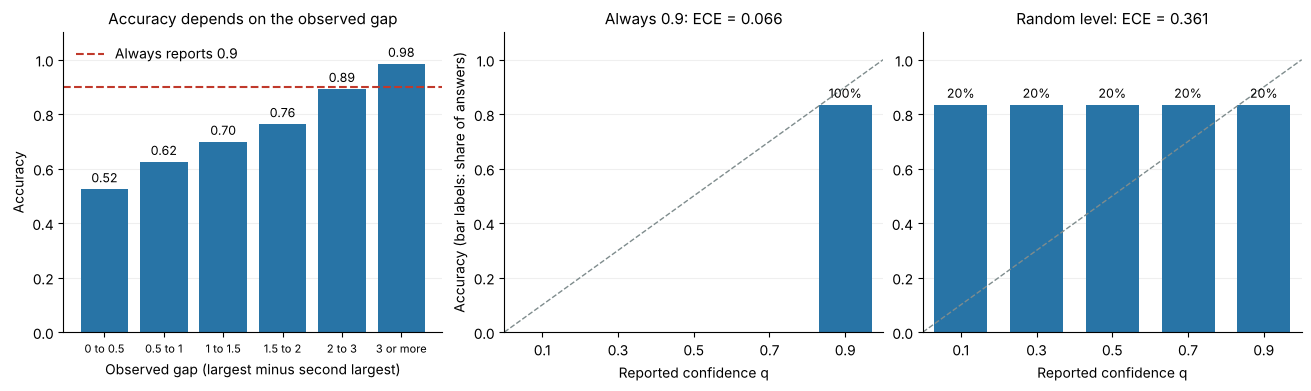

In [4]:
LEVELS = torch.tensor([0.1, 0.3, 0.5, 0.7, 0.9])


def reliability(level_weights, correct, levels):
    # level_weights[m, k] = probability that answer m is reported with level k
    level_totals = level_weights.sum(dim=0)
    share = level_totals / level_totals.sum()
    accuracy = (level_weights * correct[:, None]).sum(dim=0) / level_totals.clamp_min(1e-12)
    ece = (share * (accuracy - levels).abs()).sum().item()
    return share, accuracy, ece


def brier(level_weights, correct, levels):
    squared_errors = (levels[None, :] - correct[:, None]) ** 2
    return ((level_weights * squared_errors).sum() / level_weights.sum()).item()


def plot_reliability(ax, share, accuracy, levels, title):
    show = share >= 0.01  # skip levels used for under 1% of answers
    ax.plot([0, 1], [0, 1], linestyle="--", color=COLORS[2], linewidth=1)
    bars = ax.bar(levels[show].tolist(), accuracy[show].tolist(), width=0.14, color=COLORS[0])
    ax.bar_label(bars, labels=[f"{s:.0%}" for s in share[show].tolist()], padding=3, fontsize=9)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.1)
    ax.set_xticks(levels.tolist())
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Reported confidence q")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)


always_high = torch.zeros(len(rule_correct), len(LEVELS))
always_high[:, -1] = 1.0
random_level = torch.full((len(rule_correct), len(LEVELS)), 1 / len(LEVELS))
reporters = {"Always 0.9": always_high, "Random level": random_level}

print(f"Accuracy of these answers: {rule_correct.mean().item():.1%}")
reporter_results = {}
for name, weights in reporters.items():
    share, accuracy, ece = reliability(weights, rule_correct, LEVELS)
    reporter_results[name] = (share, accuracy, ece)
    print("=" * 56)
    print(name.upper())
    print(f"{'Reported q':<12}{'Share':>10}{'Accuracy':>12}{'|acc - q|':>12}")
    for level, s, a in zip(LEVELS.tolist(), share.tolist(), accuracy.tolist()):
        if s > 0:
            print(f"{level:<12.1f}{s:>10.1%}{a:>12.1%}{abs(a - level):>12.3f}")
    print(f"ECE = {ece:.3f}    Mean Brier penalty (q - c)^2 = {brier(weights, rule_correct, LEVELS):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
bins = list(range(1, len(GAP_LABELS)))
bars = axes[0].bar([GAP_LABELS[b] for b in bins], [rule_accuracy_by_gap[b] for b in bins], color=COLORS[0])
axes[0].bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].axhline(0.9, color=COLORS[1], linestyle="--", label="Always reports 0.9")
axes[0].set_ylim(0, 1.1)
axes[0].set_xlabel("Observed gap (largest minus second largest)")
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Accuracy depends on the observed gap", fontsize=11)
axes[0].tick_params(axis="x", labelsize=8)
axes[0].legend(frameon=False, loc="upper left")
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)
axes[0].spines[["top", "right"]].set_visible(False)
for ax, (name, (share, accuracy, ece)) in zip(axes[1:], reporter_results.items()):
    plot_reliability(ax, share, accuracy, LEVELS, f"{name}: ECE = {ece:.3f}")
axes[1].set_ylabel("Accuracy (bar labels: share of answers)")
plt.show()

Both reporters attach confidence to the same answers, which are correct 83.4% of the time.

- **Always 0.9** has a single bar slightly below the diagonal: it is overconfident on average, with ECE 0.066. The left panel shows what this average hides. When the observed gap is small, the answers are right only about half the time, yet the reporter still says 0.9. On the easiest prompts, it is slightly underconfident.
- **Random level** has ECE 0.361. Every level has the same accuracy, so its reports say nothing about which answers are right.

ECE alone is not the whole story. A reporter that always stated the overall accuracy, 0.834, would have an ECE of 0, yet it would treat a near coin flip and a near-certain answer the same way. The Brier penalty printed above also scores this difference, as Section 2 explains.

## 2 · Proper scoring rules

To train a policy to report calibrated confidence, we need a reward for the report. A good reward should make the honest report the best one. Fix a prompt and an answer, and let

$$
p=P(c=1\mid \text{what the model saw and its answer})
$$

be the true probability that this answer is correct. A scoring rule is **proper** if, on average over $c$, the report $q=p$ scores at least as well as any other report; it is **strictly proper** if $q=p$ is the only best report.

**Brier penalty:** The Brier penalty is the squared error $(q-c)^2$. Its expected value is

$$
\mathbb{E}\bigl[(q-c)^2\bigr]
= p(1-q)^2+(1-p)q^2
= q^2-2pq+p
= (q-p)^2+p(1-p)
$$

The last form shows the answer directly. The term $p(1-p)$ does not depend on $q$, and $(q-p)^2\ge 0$ is zero only at $q=p$. So the expected Brier penalty is minimized by reporting $q=p$, and the Brier score is strictly proper. With a fixed list of levels, the best allowed report is the level closest to $p$.

**Log score:** The log score is $c\ln q+(1-c)\ln(1-q)$. Its negative is Week 1's log loss: $-\ln$ of the probability assigned to what actually happened, where the two possible outcomes are "correct" and "incorrect". The expected log score is $p\ln q+(1-p)\ln(1-q)$. Setting its derivative $p/q-(1-p)/(1-q)$ to zero gives $q=p$, so the log score is also strictly proper. It punishes confident mistakes much more severely: as $q\to1$, a wrong answer costs $-\ln(1-q)\to\infty$.

**Not every reward is proper:** A reward for correctness alone, $R=c$, ignores $q$ entirely, so it gives the confidence report no reason to be honest. A reward such as "$+q$ when correct", $R=cq$, has expected value $pq$, which increases with $q$ for every $p>0$; it pushes the report to the largest allowed value.

**The RLCR reward:** Week 5's preview gave

$$
R_{\mathrm{RLCR}}=c-(q-c)^2
$$

It is correctness minus the Brier penalty. For a fixed answer, the term $c$ does not depend on $q$, so the best report is the same as for the Brier penalty alone: the level closest to $p$.

**Plot the expected penalties:** The left panel plots the expected Brier penalty against $q$ for three values of $p$; the right panel plots the expected log loss. Dots mark the minimum of each curve. The table then fixes $p=0.7$ and compares the expected reward of each allowed level under three rewards.

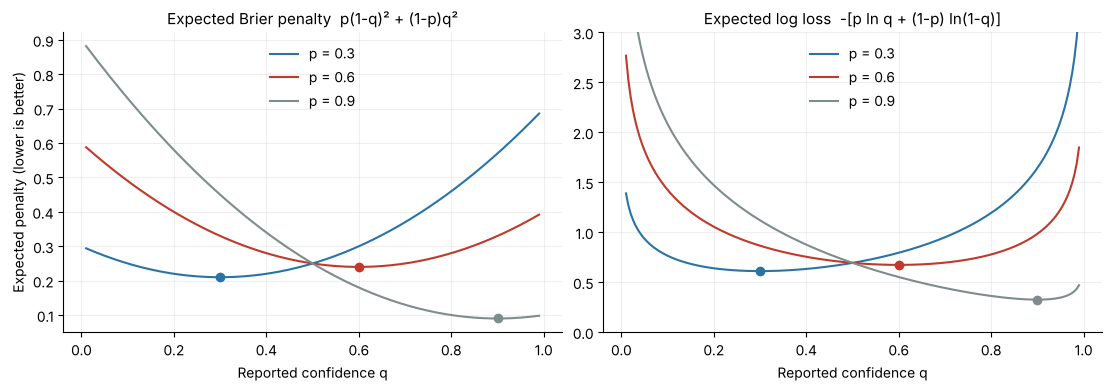

Expected reward of each report when the true probability of being correct is p = 0.7
Report q     Correctness only: c   +q when correct: cq       RLCR: c-(q-c)^2
0.1                        0.700                 0.070                 0.130
0.3                        0.700                 0.210                 0.330
0.5                        0.700                 0.350                 0.450
0.7                        0.700                 0.490                 0.490
0.9                        0.700                 0.630                 0.450
----------------------------------------------------------------------------
Best q                   all tie                   0.9                   0.7


In [5]:
q_grid = torch.linspace(0.01, 0.99, 197)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for p, color in zip((0.3, 0.6, 0.9), COLORS):
    expected_brier = p * (1 - q_grid) ** 2 + (1 - p) * q_grid ** 2
    expected_log_loss = -(p * torch.log(q_grid) + (1 - p) * torch.log(1 - q_grid))
    axes[0].plot(q_grid, expected_brier, color=color, label=f"p = {p}")
    axes[0].scatter([p], [p * (1 - p)], color=color, zorder=3)
    axes[1].plot(q_grid, expected_log_loss, color=color, label=f"p = {p}")
    best_log_loss = -(p * torch.log(torch.tensor(p)) + (1 - p) * torch.log(torch.tensor(1 - p)))
    axes[1].scatter([p], [best_log_loss], color=color, zorder=3)
axes[0].set_title("Expected Brier penalty  p(1-q)² + (1-p)q²", fontsize=11)
axes[1].set_title("Expected log loss  -[p ln q + (1-p) ln(1-q)]", fontsize=11)
axes[1].set_ylim(0, 3)
for ax in axes:
    ax.set_xlabel("Reported confidence q")
    ax.legend(frameon=False)
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Expected penalty (lower is better)")
plt.show()

p = 0.7
rewards_by_rule = {
    "Correctness only: c": [p for q in LEVELS.tolist()],
    "+q when correct: cq": [p * q for q in LEVELS.tolist()],
    "RLCR: c-(q-c)^2": [p - (p * (1 - q) ** 2 + (1 - p) * q ** 2) for q in LEVELS.tolist()],
}
print(f"Expected reward of each report when the true probability of being correct is p = {p}")
print(f"{'Report q':<10}" + "".join(f"{name:>22}" for name in rewards_by_rule))
for k, level in enumerate(LEVELS.tolist()):
    print(f"{level:<10.1f}" + "".join(f"{values[k]:>22.3f}" for values in rewards_by_rule.values()))
print("-" * 76)
best = []
for values in rewards_by_rule.values():
    top = max(values)
    winners = [f"{level:.1f}" for level, value in zip(LEVELS.tolist(), values) if abs(value - top) < 1e-9]
    best.append("all tie" if len(winners) == len(values) else ", ".join(winners))
print(f"{'Best q':<10}" + "".join(f"{text:>22}" for text in best))

In both plots, each curve reaches its minimum at $q=p$. The Brier curves are parabolas of the same shape, each centered at its own $p$. The log-loss curves rise steeply near $q=0$ and $q=1$: this is the heavy penalty for confident mistakes.

The table makes the three rewards concrete for $p=0.7$:

- **Correctness only** gives every report the same expected reward, 0.7, so it cannot teach the report anything.
- **$+q$ when correct** is best at the largest level, 0.9, even though the answer is correct only 70% of the time.
- **RLCR** is best at $q=0.7$, the honest report. Levels 0.5 and 0.9 tie at 0.45 because both are 0.2 away from $p$, as $(q-p)^2+p(1-p)$ predicts.

The same formula explains the last remark in Section 1. If $p$ varies across prompts, a constant report $q$ pays $(q-p)^2$ on every prompt whose $p$ differs from $q$. A report that follows each prompt's $p$ avoids that cost, so the Brier penalty rewards confidence that is both calibrated and informative.

## 3 · Rewarding an answer and a confidence

**A response with two parts:** As in Week 5, a response is generated one piece at a time. Here it has two pieces: first an answer $a\in\{A,B,C\}$, then a confidence level $q$. Write the response as $y=(a,q)$. Its probability is the product of the two steps, so its log-probability is a sum, just like Week 5's sum over tokens:

$$
\ln\pi_\theta(y\mid\tilde x)
=\underbrace{\ln\pi_\theta(a\mid\tilde x)}_{\text{answer}}
+\underbrace{\ln\pi_\theta(q\mid\tilde x,a)}_{\text{confidence}}
$$

**The answer head:** It is Week 4's policy, applied to the observed numbers: logits $z=Wu$ with $u=\tilde x/10$ and a $3\times3$ weight matrix $W$, followed by softmax.

**The confidence head:** It needs information about how likely the chosen answer is to be correct, so we give it one useful feature, the **gap of the chosen answer**,

$$
d=\tilde x_a-\max_{j\neq a}\tilde x_j,
$$

the chosen observed value minus the largest of the other two. It is negative when the chosen answer is not the largest observed number, and it equals Section 1's observed gap when it is. The head is a small table of logits: one row for each gap range in Section 1 (`below 0`, `0 to 0.5`, ..., `3 or more`) and one column for each confidence level. The row for the chosen answer's gap goes through softmax to give the probabilities of the five levels. This table has $7\times5=35$ weights, and $\theta$ now means $W$ together with this table. All weights start at zero, so the starting policy chooses each answer with probability $1/3$ and each level with probability $1/5$.

**Rewards and advantages:** The verifier checks the answer to obtain $c$, and the reward is $R_{\mathrm{RLCR}}=c-(q-c)^2$. We use Week 5's group-relative advantages: sample a group of $G=8$ responses to the same observed prompt and subtract the group's mean reward,

$$
A_i=r_i-\bar r,\qquad \bar r=\frac1G\sum_{i=1}^{G}r_i
$$

**Why subtract the group mean here:** In Week 5, subtracting the mean did not reduce the variance with 0/1 rewards, because 0 for a wrong answer was already a good reference point; what hurt was the 1/2 coding, where every reward was positive and every sampled response was pushed up. RLCR rewards for correct answers look like that coding: each is between $0.19$ and $0.99$. Without a baseline, every correct response would push its own confidence level up, and the policy would learn only from differences in the sizes of those pushes. After subtracting the group mean, a correct response that reported 0.5 in a group that mostly reported 0.9 receives a negative advantage. Unlike a group-relative correctness-only reward, this also gives a learning signal when all eight answers are correct, because the reported levels can differ.

<details><summary>Why we do not divide by the group standard deviation here</summary>

Week 5's GRPO advantage also divided by the group's standard deviation $s$: $A_i=(r_i-\bar r)/(s+\epsilon)$. We leave that step out today. With only the mean subtracted, the expected update is proportional to the policy gradient of expected reward. (Each $r_j$ with $j\neq i$ is independent of response $i$ given the prompt, that is, its true and observed numbers, so it acts as a baseline; the factor is $1-1/G$.) Section 2 showed that expected RLCR reward is maximized by the honest report, so this is the direction we want.

Dividing by $s$ multiplies each group's advantages by $1/s$, and $s$ depends on the sampled rewards. In this task, the eight responses in a group often share the same answer, and so the same $c$. The reward spread then depends on whether that answer is right: reporting 0.9 instead of 0.7 raises the reward by $0.99-0.91=0.08$ when the answer is correct, but lowers it by $0.81-0.49=0.32$ when the answer is wrong. Dividing by $s$ puts both kinds of group on the same scale, so the small differences in correct-answer groups, which favor higher confidence, count as much as the large differences in wrong-answer groups. The update then no longer follows the gradient of expected reward, Section 2's argument for honest reports no longer applies directly, and reported confidence can drift above the accuracy. You can test this in Section 5.

</details>

The loss for a batch of $N$ sampled responses is Week 4's reward-weighted negative log-likelihood, with advantages in place of rewards:

$$
L(\theta)=-\frac1N\sum_{i=1}^{N}A_i\Bigl[\ln\pi_\theta(a_i\mid\tilde x_i)+\ln\pi_\theta(q_i\mid\tilde x_i,a_i)\Bigr]
$$

**Score one group by hand:** The next cell defines the policy, then samples a group of eight responses from the starting policy for one noisy view of the true prompt $(2, 7, 6)$. For each response it prints the two log-probabilities and their sum, the correctness $c$, the Brier penalty, the RLCR reward, and the advantage. For comparison, the last column shows the advantage that a correctness-only reward $R=c$ would give the same responses.

In [6]:
GROUP_SIZE = 8


def gap_for_each_answer(observed):
    # d_j = observed value of answer j minus the largest other observed value
    gaps = []
    for j in range(3):
        others = torch.cat([observed[..., :j], observed[..., j + 1:]], dim=-1)
        gaps.append(observed[..., j] - others.max(dim=-1).values)
    return torch.stack(gaps, dim=-1)


class CalibratedPolicy(nn.Module):
    def __init__(self, num_levels):
        super().__init__()
        self.answer_head = nn.Linear(3, 3, bias=False)  # Week 4's 3x3 weights W
        nn.init.zeros_(self.answer_head.weight)
        # One row of logits per gap range, one column per confidence level.
        self.confidence_table = nn.Parameter(torch.zeros(len(GAP_LABELS), num_levels))

    def answer_distribution(self, observed):
        return Categorical(logits=self.answer_head(observed / 10.0))

    def confidence_distribution(self, observed, answers):
        gaps = gap_for_each_answer(observed).gather(-1, answers.unsqueeze(-1)).squeeze(-1)
        return Categorical(logits=self.confidence_table[gap_bin(gaps)])


def sample_responses(policy, observed):
    answer_dist = policy.answer_distribution(observed)
    answers = answer_dist.sample()
    confidence_dist = policy.confidence_distribution(observed, answers)
    level_index = confidence_dist.sample()
    return answers, level_index, answer_dist.log_prob(answers), confidence_dist.log_prob(level_index)


def compute_rewards(c, q, reward_name):
    if reward_name == "correctness":
        return c
    return c - (q - c) ** 2  # RLCR: correctness minus the Brier penalty


def group_advantages(rewards, divide_by_std=False):
    # rewards: one row per prompt, one column per sampled response
    centered = rewards - rewards.mean(dim=1, keepdim=True)
    if divide_by_std:  # Week 5's GRPO scaling; used only if you choose it in Section 5
        return centered / (rewards.std(dim=1, correction=0, keepdim=True) + 1e-6)
    return centered


torch.manual_seed(SEED)
start_policy = CalibratedPolicy(len(LEVELS))
demo_true = torch.tensor([[2.0, 7.0, 6.0]])
demo_observed = observe(demo_true, SIGMA)
group_true = demo_true.repeat(GROUP_SIZE, 1)
group_observed = demo_observed.repeat(GROUP_SIZE, 1)

answers, level_index, answer_log_probs, confidence_log_probs = sample_responses(start_policy, group_observed)
q = LEVELS[level_index]
c = correctness(group_true, answers)
rlcr_rewards = compute_rewards(c, q, "rlcr")
rlcr_advantages = group_advantages(rlcr_rewards.view(1, -1)).view(-1)
correctness_advantages = group_advantages(compute_rewards(c, q, "correctness").view(1, -1)).view(-1)
demo_gaps = gap_for_each_answer(demo_observed)[0]

print(f"True numbers: {tuple(int(v) for v in demo_true[0])}    (hidden from the model)")
print(format_prompt(demo_observed[0].tolist()))
print("Gap d of each possible answer: "
      + "   ".join(f"{letter}: {gap:+.2f}" for letter, gap in zip(LETTERS, demo_gaps.tolist())))
print("=" * 100)
print(f"{'Draw':<6}{'Response':<10}{'ln pi(a)':>10}{'ln pi(q|a)':>12}{'Sum':>9}{'c':>5}"
      f"{'(q-c)^2':>10}{'Reward':>9}{'Advantage':>12}{'Correctness-only adv.':>24}")
print("-" * 100)
for i in range(GROUP_SIZE):
    response = f"{LETTERS[answers[i]]} {q[i].item():.1f}"
    print(f"{i + 1:<6}{response:<10}{answer_log_probs[i].item():>10.4f}{confidence_log_probs[i].item():>12.4f}"
          f"{(answer_log_probs[i] + confidence_log_probs[i]).item():>9.4f}{int(c[i]):>5}"
          f"{((q[i] - c[i]) ** 2).item():>10.2f}{rlcr_rewards[i].item():>9.3f}"
          f"{rlcr_advantages[i].item():>12.3f}{correctness_advantages[i].item():>24.3f}")
print("-" * 100)
print(f"Group mean reward: RLCR {rlcr_rewards.mean().item():.3f} | correctness only {c.mean().item():.3f}")

True numbers: (2, 7, 6)    (hidden from the model)
Which number is largest?
A: -0.2    B: 8.6    C: 4.8
Respond with A, B, or C, then your confidence that the answer is correct.
Gap d of each possible answer: A: -8.79   B: +3.79   C: -3.79
Draw  Response    ln pi(a)  ln pi(q|a)      Sum    c   (q-c)^2   Reward   Advantage   Correctness-only adv.
----------------------------------------------------------------------------------------------------
1     A 0.1        -1.0986     -1.6094  -2.7081    0      0.01   -0.010       0.160                  -0.250
2     A 0.1        -1.0986     -1.6094  -2.7081    0      0.01   -0.010       0.160                  -0.250
3     C 0.9        -1.0986     -1.6094  -2.7081    0      0.81   -0.810      -0.640                  -0.250
4     C 0.7        -1.0986     -1.6094  -2.7081    0      0.49   -0.490      -0.320                  -0.250
5     B 0.1        -1.0986     -1.6094  -2.7081    1      0.81    0.190       0.360                   0.750
6     C 0.7

Noise made this view of $(2,7,6)$ easy: `B` looks largest by 3.79, and `B` is correct. The starting policy does not use this information yet. Every response has the same log-probabilities, $\ln(1/3)\approx-1.0986$ for the answer and $\ln(1/5)\approx-1.6094$ for the level, because all weights are still zero. The advantages therefore come entirely from the rewards.

- **Correct answers:** Draws 5 and 7 both answer `B`. `B 0.5` earns 0.75, but `B 0.1` earns only 0.19, because the Brier penalty charges for low confidence in a correct answer. Both receive positive advantages; `B 0.5` receives the larger one.
- **Wrong answers:** Draws 1 and 2 answer `A` but report 0.1. Their reward, −0.01, is above the group mean, so their advantage is positive: honest low confidence in a wrong answer is encouraged relative to the rest of the group. Draw 3, `C 0.9`, receives the most negative advantage.
- **Correctness only:** The last column ignores $q$: every wrong response gets −0.25 and both correct responses get +0.75, whatever confidence they reported.

The advantage multiplies the *sum* of both log-probabilities, so draws 1 and 2 also nudge up the probability of the wrong answer `A` for this prompt. This is the situation from Week 5's question about `B A C` in a small form: one number scores the whole response, so both parts receive the same advantage. On average it does not mislead the answer head, because for any reported level $q$, a correct answer earns $1-(1-q)^2$ and a wrong one earns $-q^2$, a difference of $2q>0$.

## 4 · Training with and without the calibration reward

We now train two policies from the same uniform start, with the same random seed, optimizer, settings, and number of sampled responses:

- **(a) Correctness-only reward**, $R=c$. Since this reward does not depend on $q$, the confidence part of the loss has zero expected gradient: the reward gives the confidence head no signal. To keep the comparison clean, the optimizer updates only the answer head, so the confidence table stays at its uniform start.
- **(b) RLCR reward**, $R=c-(q-c)^2$. The optimizer updates both heads.

**Repeat the sample → verify → update cycle:** At each update, we draw 16 training prompts with replacement, add fresh noise to each, and sample a group of $G=8$ responses for each noisy prompt: 128 responses per update. We compute group-relative advantages within each group and take one Adam step with learning rate 0.05. We run 800 updates.

**Evaluate exactly:** For a given observed prompt there are only $3\times5=15$ possible responses, so, as with Week 4's expected reward, we compute each metric exactly by weighting every possible response by its probability rather than sampling. Expected accuracy is $\sum_a\pi_\theta(a\mid\tilde x)\,c(a)$, averaged over prompts. For the reliability diagram and ECE, each response contributes its probability to the bin of its confidence level. Every 100 updates, the code reports expected accuracy and ECE on a **monitoring set**: each training prompt once, with one fixed noise draw. The test set is used only after training.

**Predict before running:** both policies learn to answer with the same kind of feedback about correctness. Which one will end with higher accuracy, and which will have the lower ECE?

MONITORING SET (training prompts, one fixed noise draw each)
            Correctness-only reward           RLCR reward         
Updates     Exp. accuracy      ECE      Exp. accuracy      ECE    
------------------------------------------------------------------
100                 65.3%    0.271              65.1%    0.067
200                 72.1%    0.293              72.1%    0.052
300                 74.5%    0.307              74.6%    0.046
400                 75.9%    0.315              76.0%    0.044
500                 76.6%    0.320              76.8%    0.042
600                 77.6%    0.325              77.6%    0.038
700                 77.9%    0.328              78.1%    0.038
800                 78.5%    0.331              78.6%    0.039


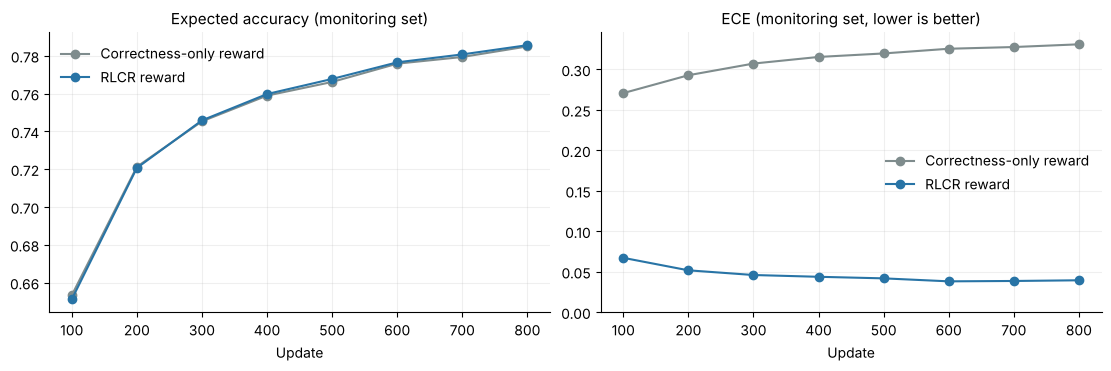

In [7]:
PROMPTS_PER_UPDATE = 16
NUM_UPDATES = 800
LEARNING_RATE = 0.05
REPORT_EVERY = 100

monitor_true = train_numbers
monitor_observed = observe(train_numbers, SIGMA, torch.Generator().manual_seed(SEED + 1))


@torch.no_grad()
def evaluate(policy, true_numbers, observed, levels):
    answer_probs = policy.answer_distribution(observed).probs                          # (N, 3)
    gaps = gap_for_each_answer(observed)                                                # (N, 3)
    confidence_probs = torch.softmax(policy.confidence_table[gap_bin(gaps)], dim=-1)    # (N, 3, K)
    joint = answer_probs.unsqueeze(-1) * confidence_probs                               # (N, 3, K)
    correct = torch.stack([
        correctness(true_numbers, torch.full((len(observed),), j)) for j in range(3)
    ], dim=1)                                                                           # (N, 3)
    share, level_accuracy, ece = reliability(joint.reshape(-1, len(levels)), correct.reshape(-1), levels)
    c = correct.unsqueeze(-1)
    per_prompt_accuracy = (answer_probs * correct).sum(dim=1)
    per_prompt_confidence = (joint * levels).sum(dim=(1, 2))
    return {
        "expected_accuracy": per_prompt_accuracy.mean().item(),
        "greedy_accuracy": correct.gather(1, answer_probs.argmax(dim=1, keepdim=True)).mean().item(),
        "mean_confidence": per_prompt_confidence.mean().item(),
        "ece": ece,
        "brier": (joint * (levels - c) ** 2).sum(dim=(1, 2)).mean().item(),
        "share": share,
        "level_accuracy": level_accuracy,
        "per_prompt_accuracy": per_prompt_accuracy,
        "per_prompt_confidence": per_prompt_confidence,
    }


def train_policy(reward_name, sigma=SIGMA, levels=LEVELS, divide_by_std=False, monitor=True, seed=SEED):
    torch.manual_seed(seed)
    policy = CalibratedPolicy(len(levels))
    if reward_name == "rlcr":
        parameters = policy.parameters()
    else:
        parameters = policy.answer_head.parameters()  # confidence table stays at its start
    optimizer = torch.optim.Adam(parameters, lr=LEARNING_RATE)
    history = []
    for update in range(1, NUM_UPDATES + 1):
        indices = torch.randint(len(train_numbers), (PROMPTS_PER_UPDATE,))
        true_numbers = train_numbers[indices].repeat_interleave(GROUP_SIZE, dim=0)
        observed = observe(train_numbers[indices], sigma).repeat_interleave(GROUP_SIZE, dim=0)

        answers, level_index, answer_log_probs, confidence_log_probs = sample_responses(policy, observed)
        c = correctness(true_numbers, answers)
        rewards = compute_rewards(c, levels[level_index], reward_name)
        advantages = group_advantages(rewards.view(PROMPTS_PER_UPDATE, GROUP_SIZE), divide_by_std).view(-1)
        loss = -(advantages * (answer_log_probs + confidence_log_probs)).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if monitor and update % REPORT_EVERY == 0:
            metrics = evaluate(policy, monitor_true, monitor_observed, levels)
            history.append({"update": update, **metrics})
    return policy, history


REWARD_NAMES = {"correctness": "Correctness-only reward", "rlcr": "RLCR reward"}
policies, histories = {}, {}
for reward_name in REWARD_NAMES:
    policies[reward_name], histories[reward_name] = train_policy(reward_name)

print("MONITORING SET (training prompts, one fixed noise draw each)")
print(f"{'':<10}{'Correctness-only reward':^28}{'RLCR reward':^28}")
print(f"{'Updates':<10}" + f"{'Exp. accuracy':>15}{'ECE':>9}    " * 2)
print("-" * 66)
for row_a, row_b in zip(histories["correctness"], histories["rlcr"]):
    print(f"{row_a['update']:<10}"
          f"{row_a['expected_accuracy']:>15.1%}{row_a['ece']:>9.3f}    "
          f"{row_b['expected_accuracy']:>15.1%}{row_b['ece']:>9.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
for (reward_name, label), color in zip(REWARD_NAMES.items(), (COLORS[2], COLORS[0])):
    steps = [row["update"] for row in histories[reward_name]]
    axes[0].plot(steps, [row["expected_accuracy"] for row in histories[reward_name]],
                 marker="o", color=color, label=label)
    axes[1].plot(steps, [row["ece"] for row in histories[reward_name]],
                 marker="o", color=color, label=label)
axes[0].set_title("Expected accuracy (monitoring set)", fontsize=11)
axes[1].set_title("ECE (monitoring set, lower is better)", fontsize=11)
for ax in axes:
    ax.set_xlabel("Update")
    ax.legend(frameon=False)
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[1].set_ylim(bottom=0)
plt.show()

On the monitoring set, the two policies' expected accuracy rises together and stays nearly identical at every checkpoint: adding the calibration term did not slow down learning to answer.

Their ECE separates immediately. The RLCR policy's ECE falls below 0.05 within the first few hundred updates. The correctness-only policy's ECE slowly *rises*: its confidence is still chosen at random with an average of 0.5, so as its answers improve, its accuracy moves further from most of the levels it reports.

**Compare the policies on the test set:** The table reports, for the starting policy and both trained policies:

| Quantity | What it tells us |
|---|---|
| Expected accuracy | Chance that a sampled answer is correct |
| Greedy accuracy | Accuracy if we always choose the most likely answer |
| Mean $q$ | Average reported confidence |
| ECE | Calibration error across the five levels (lower is better) |
| Brier | Average Brier penalty $(q-c)^2$ (lower is better) |

For reference, the last row repeats Section 1's largest-observed answers with confidence always 0.9. The cell then prints the RLCR policy's share and accuracy for each level, and the reliability diagrams compare the starting policy with the two trained policies; bar labels give each level's share of responses, and levels used for under 1% of responses are not drawn.

TEST SET | 1200 observed prompts
Policy                        Exp. acc.   Greedy   Mean q     ECE   Brier
-------------------------------------------------------------------------
Starting policy                   33.3%    33.3%    0.500   0.273   0.330
Correctness-only reward           79.4%    83.0%    0.500   0.337   0.330
RLCR reward                       79.5%    83.0%    0.770   0.034   0.115
-------------------------------------------------------------------------
Largest observed, q = 0.9         83.4%    83.4%    0.900   0.066   0.143

RLCR POLICY: SHARE AND ACCURACY OF EACH REPORTED LEVEL
Reported q       Share    Accuracy
0.1               0.2%      (rare)
0.3              11.4%       29.3%
0.5               4.8%       52.7%
0.7              20.5%       68.0%
0.9              63.1%       94.4%


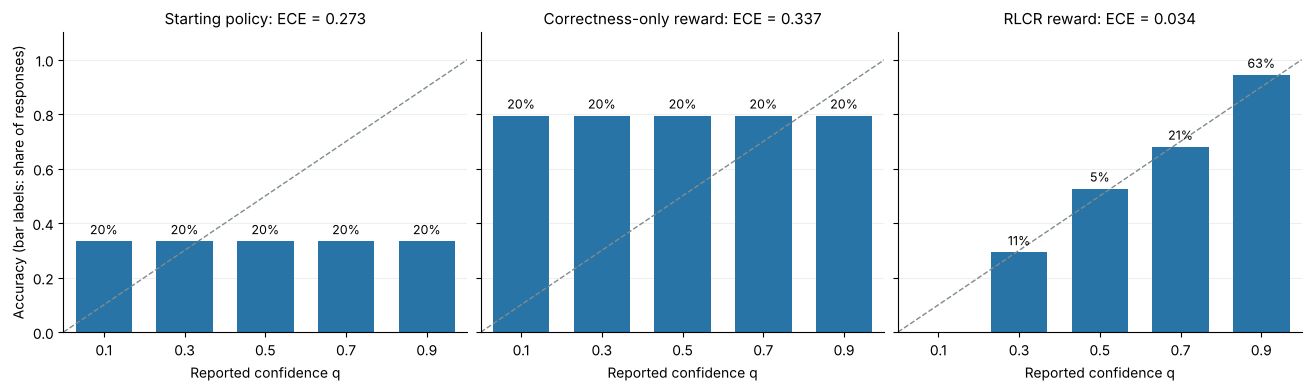

In [8]:
test_results = {"Starting policy": evaluate(start_policy, test_true, test_observed, LEVELS)}
for reward_name, label in REWARD_NAMES.items():
    test_results[label] = evaluate(policies[reward_name], test_true, test_observed, LEVELS)

rule_ece = reporter_results["Always 0.9"][2]
rule_brier = brier(always_high, rule_correct, LEVELS)

print(f"TEST SET | {len(test_observed)} observed prompts")
print(f"{'Policy':<28}{'Exp. acc.':>11}{'Greedy':>9}{'Mean q':>9}{'ECE':>8}{'Brier':>8}")
print("-" * 73)
for name, m in test_results.items():
    print(f"{name:<28}{m['expected_accuracy']:>11.1%}{m['greedy_accuracy']:>9.1%}{m['mean_confidence']:>9.3f}"
          f"{m['ece']:>8.3f}{m['brier']:>8.3f}")
print("-" * 73)
print(f"{'Largest observed, q = 0.9':<28}{rule_correct.mean().item():>11.1%}{rule_correct.mean().item():>9.1%}"
      f"{0.9:>9.3f}{rule_ece:>8.3f}{rule_brier:>8.3f}")

rlcr_test = test_results["RLCR reward"]
print("\nRLCR POLICY: SHARE AND ACCURACY OF EACH REPORTED LEVEL")
print(f"{'Reported q':<12}{'Share':>10}{'Accuracy':>12}")
for level, s, a in zip(LEVELS.tolist(), rlcr_test["share"].tolist(), rlcr_test["level_accuracy"].tolist()):
    print(f"{level:<12.1f}{s:>10.1%}{a:>12.1%}" if s >= 0.01 else f"{level:<12.1f}{s:>10.1%}{'(rare)':>12}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True, constrained_layout=True)
for ax, (name, m) in zip(axes, test_results.items()):
    plot_reliability(ax, m["share"], m["level_accuracy"], LEVELS, f"{name}: ECE = {m['ece']:.3f}")
axes[0].set_ylabel("Accuracy (bar labels: share of responses)")
plt.show()

**Accuracy is about the same:** The two trained policies have essentially the same expected accuracy on the test set (79.4% and 79.5%) and the same greedy accuracy (83.0%). The calibration reward did not cost accuracy here.

**Calibration is very different:** ECE falls from 0.337 with the correctness-only reward to 0.034 with the RLCR reward, and the Brier penalty falls from 0.330 to 0.115. The reliability diagrams show why:

- The starting policy chooses answers at random, so every bar is at 1/3.
- After correctness-only training, every bar rises to the policy's accuracy, about 0.8. The level is still chosen at random, so it has nothing to do with correctness.
- After RLCR training, the bars lie close to the diagonal. Levels 0.3, 0.5, and 0.7 are each close to their accuracy. Level 0.9, used for most responses, is slightly underconfident: its answers are correct about 94% of the time. Level 0.1 is almost never used.

**The reference row:** The largest-observed rule is somewhat more accurate than the trained policies' sampled answers. It always picks the largest observed number, while the trained answer head still samples other answers some of the time; the trained policies' greedy accuracy is close to the rule's. Even with less accurate answers, the RLCR policy has a lower ECE and a lower Brier penalty than always reporting 0.9.

**Does confidence follow difficulty?** ECE groups responses by the level they report, so it can miss a policy that reports the same level for easy and hard prompts. A more direct check groups the test prompts by Section 1's observed gap and compares, within each group, the average reported confidence with the expected accuracy. The cell also prints the trained RLCR policy's confidence table after softmax: for each gap range of the chosen answer, the probability of each level.

TEST SET, GROUPED BY OBSERVED GAP
               Correctness-only reward         RLCR reward        
Observed gap    Exp. accuracy   Mean q    Exp. accuracy   Mean q  
------------------------------------------------------------------
0 to 0.5                45.7%    0.500            45.6%    0.406  
0.5 to 1                52.2%    0.500            52.1%    0.577  
1 to 1.5                61.3%    0.500            61.4%    0.628  
1.5 to 2                70.9%    0.500            71.0%    0.763  
2 to 3                  86.0%    0.500            86.1%    0.873  
3 or more               97.9%    0.500            98.0%    0.897  

RLCR POLICY: PROBABILITY OF EACH LEVEL, BY GAP OF THE CHOSEN ANSWER
Gap d            q = 0.1   q = 0.3   q = 0.5   q = 0.7   q = 0.9
below 0             0.01      0.98      0.00      0.00      0.00
0 to 0.5            0.00      0.01      0.98      0.01      0.00
0.5 to 1            0.00      0.00      0.01      0.98      0.01
1 to 1.5            0.00      0.00

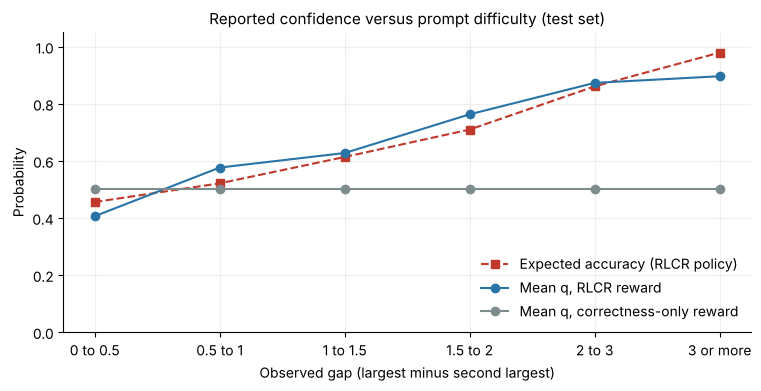

In [9]:
gap_rows = list(range(1, len(GAP_LABELS)))
summary = {}
for reward_name, label in REWARD_NAMES.items():
    m = test_results[label]
    summary[reward_name] = [
        (m["per_prompt_accuracy"][test_gap_bins == b].mean().item(),
         m["per_prompt_confidence"][test_gap_bins == b].mean().item())
        for b in gap_rows
    ]

print("TEST SET, GROUPED BY OBSERVED GAP")
print(f"{'':<14}{'Correctness-only reward':^26}{'RLCR reward':^26}")
print(f"{'Observed gap':<14}" + f"{'Exp. accuracy':>15}{'Mean q':>9}  " * 2)
print("-" * 66)
for row, (correct_row, rlcr_row) in zip(gap_rows, zip(summary["correctness"], summary["rlcr"])):
    print(f"{GAP_LABELS[row]:<14}{correct_row[0]:>15.1%}{correct_row[1]:>9.3f}  "
          f"{rlcr_row[0]:>15.1%}{rlcr_row[1]:>9.3f}  ")

print("\nRLCR POLICY: PROBABILITY OF EACH LEVEL, BY GAP OF THE CHOSEN ANSWER")
print(f"{'Gap d':<14}" + "".join(f"{f'q = {level:.1f}':>10}" for level in LEVELS.tolist()))
with torch.no_grad():
    table = torch.softmax(policies["rlcr"].confidence_table, dim=-1)
for label, row in zip(GAP_LABELS, table.tolist()):
    print(f"{label:<14}" + "".join(f"{value:>10.2f}" for value in row))

fig, ax = plt.subplots(figsize=(7.5, 3.8), constrained_layout=True)
x_labels = [GAP_LABELS[b] for b in gap_rows]
ax.plot(x_labels, [a for a, _ in summary["rlcr"]], color=COLORS[1], linestyle="--", marker="s",
        label="Expected accuracy (RLCR policy)")
ax.plot(x_labels, [q for _, q in summary["rlcr"]], color=COLORS[0], marker="o", label="Mean q, RLCR reward")
ax.plot(x_labels, [q for _, q in summary["correctness"]], color=COLORS[2], marker="o",
        label="Mean q, correctness-only reward")
ax.set_ylim(0, 1.05)
ax.set_xlabel("Observed gap (largest minus second largest)")
ax.set_ylabel("Probability")
ax.set_title("Reported confidence versus prompt difficulty (test set)", fontsize=11)
ax.legend(frameon=False, loc="lower right")
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

The correctness-only policy reports 0.5 on average in every group: its confidence ignores difficulty. The RLCR policy's average confidence rises with the observed gap and stays close to its expected accuracy within each group, from about 0.4 on the hardest prompts to about 0.9 on the easiest. The largest shortfall is in the easiest group, where accuracy is about 98% but 0.9 is the highest level allowed.

The confidence table shows the rule the policy learned. It reports 0.3 when the chosen answer is not the largest observed number; such answers are right about 30% of the time (the 0.3 bar above). It reports 0.5 for gaps from 0 to 0.5, 0.7 for gaps from 0.5 to 1.5, and 0.9 for gaps of 2 or more. In these rows it picks the level closest to Section 1's accuracy for that range, as Section 2 predicts. The head sees only the gap range, not the exact prompt, and $p$ varies among prompts in the same range. Averaging Section 2's formula over those prompts gives $\mathbb{E}[(q-p)^2]=(q-\bar p)^2+\mathrm{Var}(p)$, where $\bar p$ is the range's average probability of being correct, so the best level is the one closest to the range's average accuracy. The row for gaps from 1.5 to 2 still mixes 0.7 and 0.9, although 0.7 is closer to that range's accuracy (about 76%); 800 noisy updates have not fully settled it.

## 5 · Try it

**Inspect an individual prompt:** Set `OBSERVED` to three observed values, as the model would see them after noise. The cell prints both trained policies' answer probabilities. For each policy's most likely answer, it prints the gap $d$ and the probability of each confidence level, along with the accuracy of the largest-observed rule on test prompts in the same gap range (Section 1). This only evaluates the trained policies; it does not update them.

**Predict before running:** the default values have two close observations, 7.1 and 6.4. What confidence should a calibrated policy report for answer `B`? What will each trained policy report?

In [10]:
OBSERVED = (6.4, 7.1, 2.8)

if len(OBSERVED) != 3 or len(set(OBSERVED)) != 3:
    raise ValueError("Choose three different observed values.")

observed = torch.tensor([OBSERVED], dtype=torch.float32)
print(format_prompt(OBSERVED))
print("=" * 68)
with torch.no_grad():
    for reward_name, label in REWARD_NAMES.items():
        policy = policies[reward_name]
        answer_probs = policy.answer_distribution(observed).probs[0]
        answer = answer_probs.argmax().unsqueeze(0)
        gap = gap_for_each_answer(observed)[0, answer].item()
        level_probs = policy.confidence_distribution(observed, answer).probs[0]
        print(label.upper())
        print("Answer probabilities: "
              + "   ".join(f"{letter}: {p:.3f}" for letter, p in zip(LETTERS, answer_probs.tolist())))
        print(f"Most likely answer: {LETTERS[answer.item()]}   gap d = {gap:+.2f} ({GAP_LABELS[gap_bin(torch.tensor(gap)).item()]})")
        print("Confidence levels:    "
              + "   ".join(f"{level:.1f}: {p:.2f}" for level, p in zip(LEVELS.tolist(), level_probs.tolist())))
        print(f"Mean reported q for this answer: {(level_probs * LEVELS).sum().item():.3f}")
        print("-" * 68)
b = gap_bin(observed_gap(observed))[0].item()
print(f"Largest-observed rule on test prompts with observed gap {GAP_LABELS[b]}: {rule_accuracy_by_gap[b]:.1%} correct")

Which number is largest?
A: 6.4    B: 7.1    C: 2.8
Respond with A, B, or C, then your confidence that the answer is correct.
CORRECTNESS-ONLY REWARD
Answer probabilities: A: 0.347   B: 0.652   C: 0.002
Most likely answer: B   gap d = +0.70 (0.5 to 1)
Confidence levels:    0.1: 0.20   0.3: 0.20   0.5: 0.20   0.7: 0.20   0.9: 0.20
Mean reported q for this answer: 0.500
--------------------------------------------------------------------
RLCR REWARD
Answer probabilities: A: 0.353   B: 0.645   C: 0.002
Most likely answer: B   gap d = +0.70 (0.5 to 1)
Confidence levels:    0.1: 0.00   0.3: 0.00   0.5: 0.01   0.7: 0.98   0.9: 0.01
Mean reported q for this answer: 0.698
--------------------------------------------------------------------
Largest-observed rule on test prompts with observed gap 0.5 to 1: 62.4% correct


Both policies prefer `B` but are far from certain: each gives `A` about 35% probability. The answer head's logits are linear in the observed values divided by 10, so a gap of 0.7 moves the logits only a little unless the weights become very large, and near-ties give a weak reward signal. The correctness-only policy reports every level with probability 0.2, an average of 0.5, as it does for every prompt. The RLCR policy reports 0.7 almost every time. On test prompts with an observed gap from 0.5 to 1, the largest-observed answer is right about 62% of the time, and 0.7 is the allowed level closest to that. If the RLCR policy samples `A` instead, the gap of its answer is negative and it reports 0.3.

**Try it:** move `B` far above the others, for example `(6.4, 9.5, 2.8)`, or make the two largest values nearly equal, for example `(6.4, 6.5, 2.8)`. Predict the RLCR policy's confidence before running the cell. With nearly equal values, check which answer the policy prefers and what gap $d$ that answer has: the answer head's weights are learned from noisy samples, so they need not split near-ties exactly in favor of the larger value.

**Change the noise or the confidence levels, then retrain:** The cell below retrains the RLCR policy with your settings (800 updates, a few seconds) and compares it with Section 4's RLCR policy on a test set observed at your noise level. By default it keeps $\sigma=1.5$ and adds a sixth level, 0.99. You can also set `DIVIDE_BY_STD = True` to use Week 5's advantage $(r_i-\bar r)/(s+\epsilon)$ instead of $r_i-\bar r$.

**Predict before running:** in Section 4, the RLCR policy reported 0.9 for the easiest prompts. What will it report for those prompts once 0.99 is allowed, and what will happen to ECE and the Brier penalty?

In [11]:
NEW_SIGMA = 1.5
NEW_LEVELS = (0.1, 0.3, 0.5, 0.7, 0.9, 0.99)
DIVIDE_BY_STD = False

if not 0 < NEW_SIGMA <= 5:
    raise ValueError("Choose a noise level between 0 and 5.")
if any(not 0 < level < 1 for level in NEW_LEVELS) or list(NEW_LEVELS) != sorted(set(NEW_LEVELS)):
    raise ValueError("Choose increasing confidence levels strictly between 0 and 1.")


new_levels = torch.tensor(NEW_LEVELS)
new_true = test_numbers.repeat(TEST_DRAWS, 1)
new_observed = observe(new_true, NEW_SIGMA, torch.Generator().manual_seed(SEED))
new_policy, _ = train_policy("rlcr", sigma=NEW_SIGMA, levels=new_levels,
                              divide_by_std=DIVIDE_BY_STD, monitor=False)
new_result = evaluate(new_policy, new_true, new_observed, new_levels)
section4 = test_results["RLCR reward"]

print(f"{'Setting':<34}{'Exp. acc.':>11}{'Mean q':>9}{'ECE':>8}{'Brier':>8}")
print("-" * 70)
for name, m in [(f"Section 4 (sigma = {SIGMA})", section4), (f"New policy (sigma = {NEW_SIGMA})", new_result)]:
    print(f"{name:<34}{m['expected_accuracy']:>11.1%}{m['mean_confidence']:>9.3f}{m['ece']:>8.3f}{m['brier']:>8.3f}")
print("\nNEW POLICY: SHARE AND ACCURACY OF EACH REPORTED LEVEL")
print(f"{'Reported q':<12}{'Share':>10}{'Accuracy':>12}")
for level, s, a in zip(NEW_LEVELS, new_result["share"].tolist(), new_result["level_accuracy"].tolist()):
    print(f"{level:<12}{s:>10.1%}{a:>12.1%}" if s >= 0.01 else f"{level:<12}{s:>10.1%}{'(rare)':>12}")

new_bins = gap_bin(observed_gap(new_observed))
print("\nNEW POLICY, GROUPED BY OBSERVED GAP")
print(f"{'Observed gap':<14}{'Exp. accuracy':>15}{'Mean q':>9}")
for b in range(1, len(GAP_LABELS)):
    in_bin = new_bins == b
    print(f"{GAP_LABELS[b]:<14}{new_result['per_prompt_accuracy'][in_bin].mean().item():>15.1%}"
          f"{new_result['per_prompt_confidence'][in_bin].mean().item():>9.3f}")

Setting                             Exp. acc.   Mean q     ECE   Brier
----------------------------------------------------------------------
Section 4 (sigma = 1.5)                 79.5%    0.770   0.034   0.115
New policy (sigma = 1.5)                79.5%    0.797   0.009   0.112

NEW POLICY: SHARE AND ACCURACY OF EACH REPORTED LEVEL
Reported q       Share    Accuracy
0.1               0.3%      (rare)
0.3              11.2%       29.0%
0.5               6.1%       54.7%
0.7              23.3%       69.9%
0.9              17.9%       89.3%
0.99             41.3%       98.2%

NEW POLICY, GROUPED BY OBSERVED GAP
Observed gap    Exp. accuracy   Mean q
0 to 0.5                46.0%    0.414
0.5 to 1                52.5%    0.561
1 to 1.5                61.6%    0.626
1.5 to 2                70.3%    0.660
2 to 3                  85.9%    0.874
3 or more               97.9%    0.984


With 0.99 available, the policy uses it for about 41% of responses: the easiest prompts, whose answers are correct about 98% of the time. In the grouped table, the easiest group's mean $q$ rises from about 0.90 in Section 4 to about 0.98, matching its accuracy. ECE falls from 0.034 to 0.009 and the Brier penalty also falls slightly, while accuracy is unchanged. When the allowed levels can match the true probabilities more closely, the policy reports more accurate confidence.

**Try it:** change one setting at a time and rerun the cell.

- Set `NEW_SIGMA = 1.0` or `2.0`. **What to expect:** less noise makes more prompts easy, so accuracy and average confidence both rise; more noise lowers both. Check whether mean $q$ still follows the expected accuracy across the gap groups.
- Restore the five original levels with `NEW_SIGMA = 1.5`. The results match Section 4 exactly, because training uses the same seed.
- Allow only two levels, `(0.5, 0.9)`. Predict which gap groups will receive each level.
- Set `DIVIDE_BY_STD = True`. **Discuss:** compare the grouped table with the one above. On moderately hard prompts, does mean $q$ still follow the expected accuracy? Relate your answer to the note in Section 3.

### How this maps to a language model

In the RLCR paper, a language model writes its reasoning, an answer, a short analysis of its uncertainty, and then a numerical confidence. A verifier checks the answer to obtain $c$, the stated confidence is read off as $q$, and the reward $c-(q-c)^2$ scores both parts of the response. The paper trains with GRPO, so each prompt receives a group of sampled responses whose rewards are compared within the group, as in Week 5 and today.

Two differences from our small policy are worth keeping in mind. First, the confidence is itself a few generated tokens (for example, `0.7`), so its log-probability is a sum over those tokens, and the whole response's log-probability adds the answer and confidence tokens together, as in today's two-part sum. Second, a language model has no hand-made gap feature: it must learn from its own reasoning and internal state which questions are hard. Our confidence head was given a useful feature, which is why it could learn quickly.

## Recap

We trained a policy to give an answer and to report how likely that answer is to be correct:

**Noisy prompt → answer and confidence → verifier checks the answer → reward c − (q − c)² → group-relative advantages → weight update**

Calibration asks that answers reported with confidence $q$ be correct about a fraction $q$ of the time; reliability diagrams and ECE measure it. A reward based on correctness alone says nothing about $q$, and a reward such as $+q$ when correct pushes $q$ to the top. The Brier penalty is a strictly proper scoring rule, so subtracting it from correctness makes the honest report the best one. Trained with group-relative advantages, the RLCR policy matched the correctness-only policy's accuracy and became much better calibrated, with confidence that rose with the observed gap.

### Check your understanding

1. Suppose the true probability that an answer is correct is $p=0.65$ and the allowed levels are $0.1, 0.3, 0.5, 0.7, 0.9$. Which level maximizes the expected RLCR reward, and why?
2. Why does the reward $R=cq$ ("$+q$ when correct") lead to overconfidence?
3. In a group of eight responses to the same prompt, all eight answers are correct. What advantages does the correctness-only reward give? What about the RLCR reward?
4. A policy that always reports its overall accuracy (for example, $q=0.8$ for every answer when 80% of its answers are correct) has an ECE of about zero. Why is it still a poor confidence report, and which measure from today shows this?

<details><summary>Answers</summary>

1. The level 0.7. The expected Brier penalty is $(q-p)^2+p(1-p)$, so the best level is the one closest to $p$: 0.7 is 0.05 away and 0.5 is 0.15 away. The term $c$ in the RLCR reward does not depend on $q$.
2. Its expected value is $pq$, which increases with $q$ whenever $p>0$. The best report is therefore the largest allowed level, regardless of how likely the answer is to be correct.
3. Correctness only: every reward is 1, so every advantage $r_i-\bar r$ is 0 and the group gives no learning signal. RLCR: the rewards are $1-(1-q_i)^2$, which differ when the reported levels differ. Responses with higher confidence get positive advantages, so this group pushes toward higher confidence. Groups whose answers are wrong push the other way, and on average the report moves toward the level closest to $p$.
4. It does not separate easy prompts from hard ones: it gives the same confidence to an answer that is almost surely right and to a near coin flip. Its expected Brier penalty is higher than that of a report that follows each prompt's difficulty, because $\mathbb{E}[(q-c)^2]=(q-p)^2+p(1-p)$ adds $(q-p)^2$ on every prompt whose $p$ differs from the overall accuracy. Grouping by observed gap, as in Section 4, also reveals the problem: the reported confidence stays flat while accuracy rises from about one half to almost one.

</details>

### Next week: learning from preferences

So far, a verifier could check every answer. For many tasks, such as judging helpfulness or tone, no verifier exists, but people can compare two responses and say which one they prefer. Next week, we model such pairwise preferences with the Bradley–Terry model, fit a reward model to them, and see how direct preference optimization (DPO) trains a policy from preferences without fitting a separate reward model.

## References and further reading

- [Damani et al. (2025): Beyond binary rewards — training LMs to reason about their uncertainty](https://arxiv.org/abs/2507.16806): the RLCR reward, correctness minus the Brier penalty, for training language models to state calibrated confidence.
- [Gneiting and Raftery (2007): Strictly proper scoring rules, prediction, and estimation](https://doi.org/10.1198/016214506000001437): proper scoring rules, including the Brier and logarithmic scores.
- [Guo et al. (2017): On calibration of modern neural networks](https://arxiv.org/abs/1706.04599): reliability diagrams and expected calibration error.